<a href="https://colab.research.google.com/github/PR1449/TGbot/blob/main/analysis_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [20]:
df = pd.read_csv("/content/ТеплоБот.csv", encoding="utf-8")

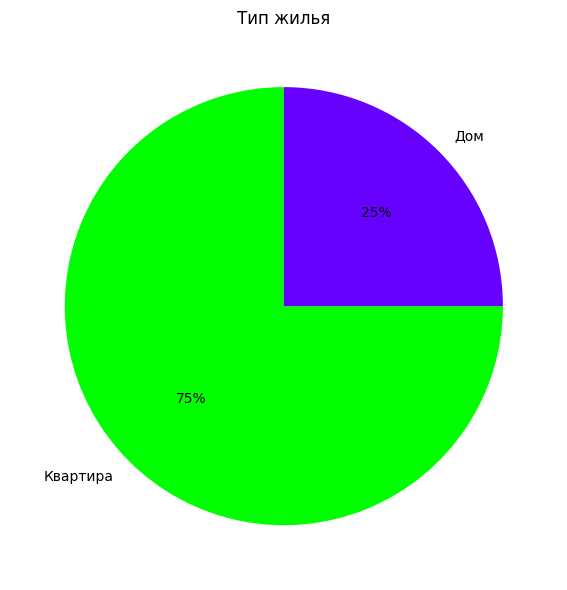

In [21]:
df.columns = [
    "timestamp", "возраст", "жильё", "температура_ок",
    "обращались_в_ук", "грубость_диспетчера", "время_дозвона",
    "оценить_связь", "эффективность_решения", "теплобот_полезен",
    "предложения", "q12", "q13", "q14", "q15", "q16",
    "q17", "q18", "q19", "q20", "район", "комментарий"
]

df["жильё"] = df["жильё"].str.strip().str.lower()
df.loc[df["жильё"] == "квартира", "жильё"] = "Квартира"
df.loc[df["жильё"] == "дом", "жильё"] = "Дом"

counts = df["жильё"].value_counts()
plt.figure(figsize=(6, 6))
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff'])
plt.title("Тип жилья")
plt.tight_layout()
plt.savefig("housing_pie.png", dpi=150)
plt.show()

In [22]:
df_all = df.copy()
df = df[df["жильё"] == "Квартира"].reset_index(drop=True)

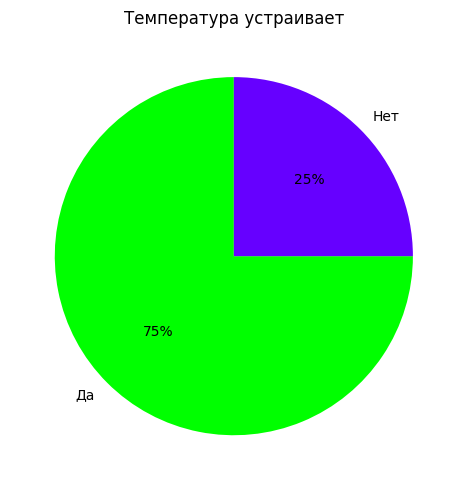

In [23]:
df["температура_ок"] = df["температура_ок"].str.strip().str.capitalize()

plt.figure(figsize=(5, 5))
counts = df["температура_ок"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff'])
plt.title("Температура устраивает")
plt.tight_layout()
plt.show()

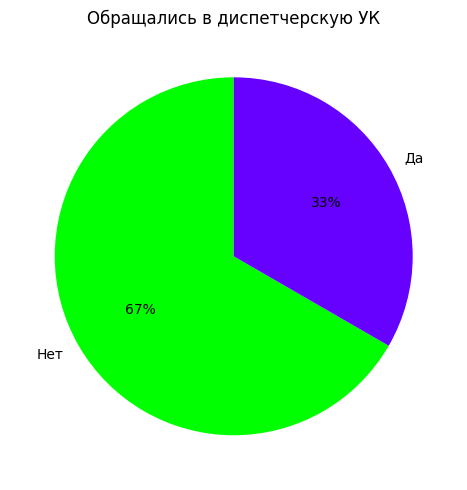

In [24]:
df["обращались_в_ук"] = df["обращались_в_ук"].str.strip().str.capitalize()

plt.figure(figsize=(5, 5))
counts = df["обращались_в_ук"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff'])
plt.title("Обращались в диспетчерскую УК")
plt.tight_layout()
plt.show()

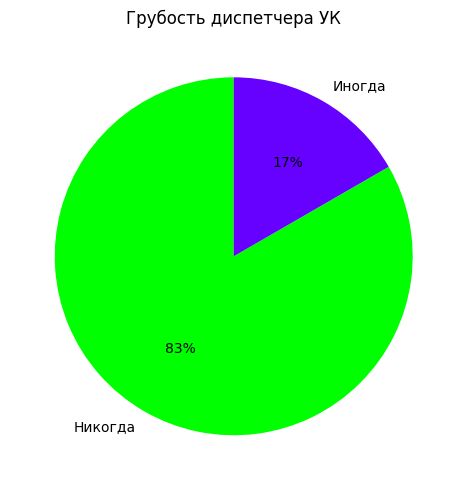

In [25]:
df["грубость_диспетчера"] = df["грубость_диспетчера"].str.strip().str.capitalize()

plt.figure(figsize=(5, 5))
counts = df["грубость_диспетчера"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff'])
plt.title("Грубость диспетчера УК")
plt.tight_layout()
plt.show()

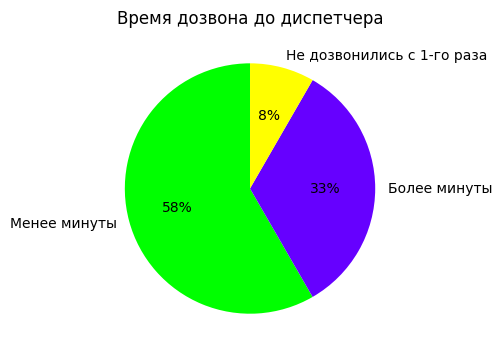

In [26]:
df["время_дозвона"] = df["время_дозвона"].str.strip()

mask = df["время_дозвона"].str.lower().isin(["менее 10 секунд", "около пол минуты"])
df.loc[mask, "время_дозвона"] = "Менее минуты"

plt.figure(figsize=(5, 5))
counts = df["время_дозвона"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff', '#ffff00'])
plt.title("Время дозвона до диспетчера")
plt.tight_layout()
plt.show()

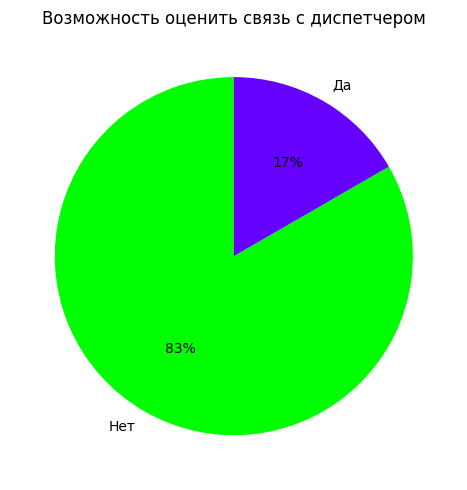

In [27]:
df["оценить_связь"] = df["оценить_связь"].str.strip().str.capitalize()

plt.figure(figsize=(5, 5))
counts = df["оценить_связь"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff'])
plt.title("Возможность оценить связь с диспетчером")
plt.tight_layout()
plt.show()

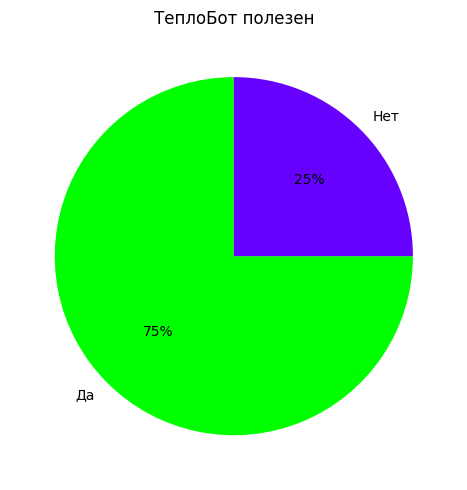

In [28]:
df["теплобот_полезен"] = df["теплобот_полезен"].str.strip().str.capitalize()

plt.figure(figsize=(5, 5))
counts = df["теплобот_полезен"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90, colors=['#00ff00', '#6600ff'])
plt.title("ТеплоБот полезен")
plt.tight_layout()
plt.show()

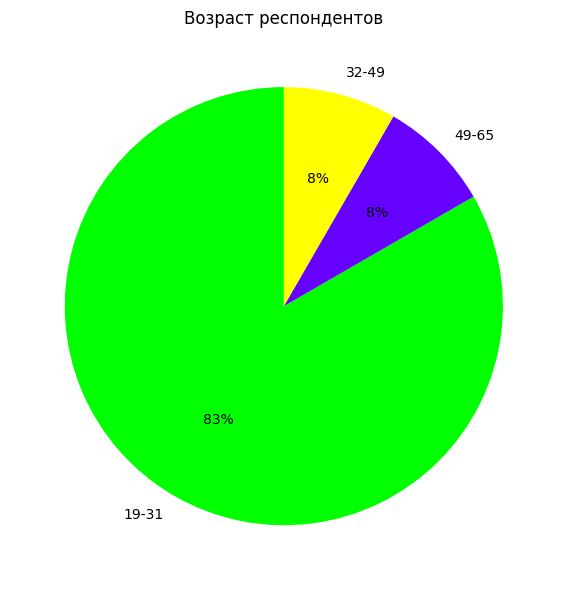

In [29]:
df["возраст"] = df["возраст"].str.strip()
df["возраст"] = df["возраст"].str.replace(r'\s*-\s*', '-', regex=True)

plt.figure(figsize=(6, 6))
counts = df["возраст"].value_counts()
plt.pie(counts, labels=counts.index, autopct="%1.0f%%", startangle=90,
        colors=['#00ff00', '#6600ff', '#ffff00', '#ff6600'])
plt.title("Возраст респондентов")
plt.tight_layout()
plt.show()

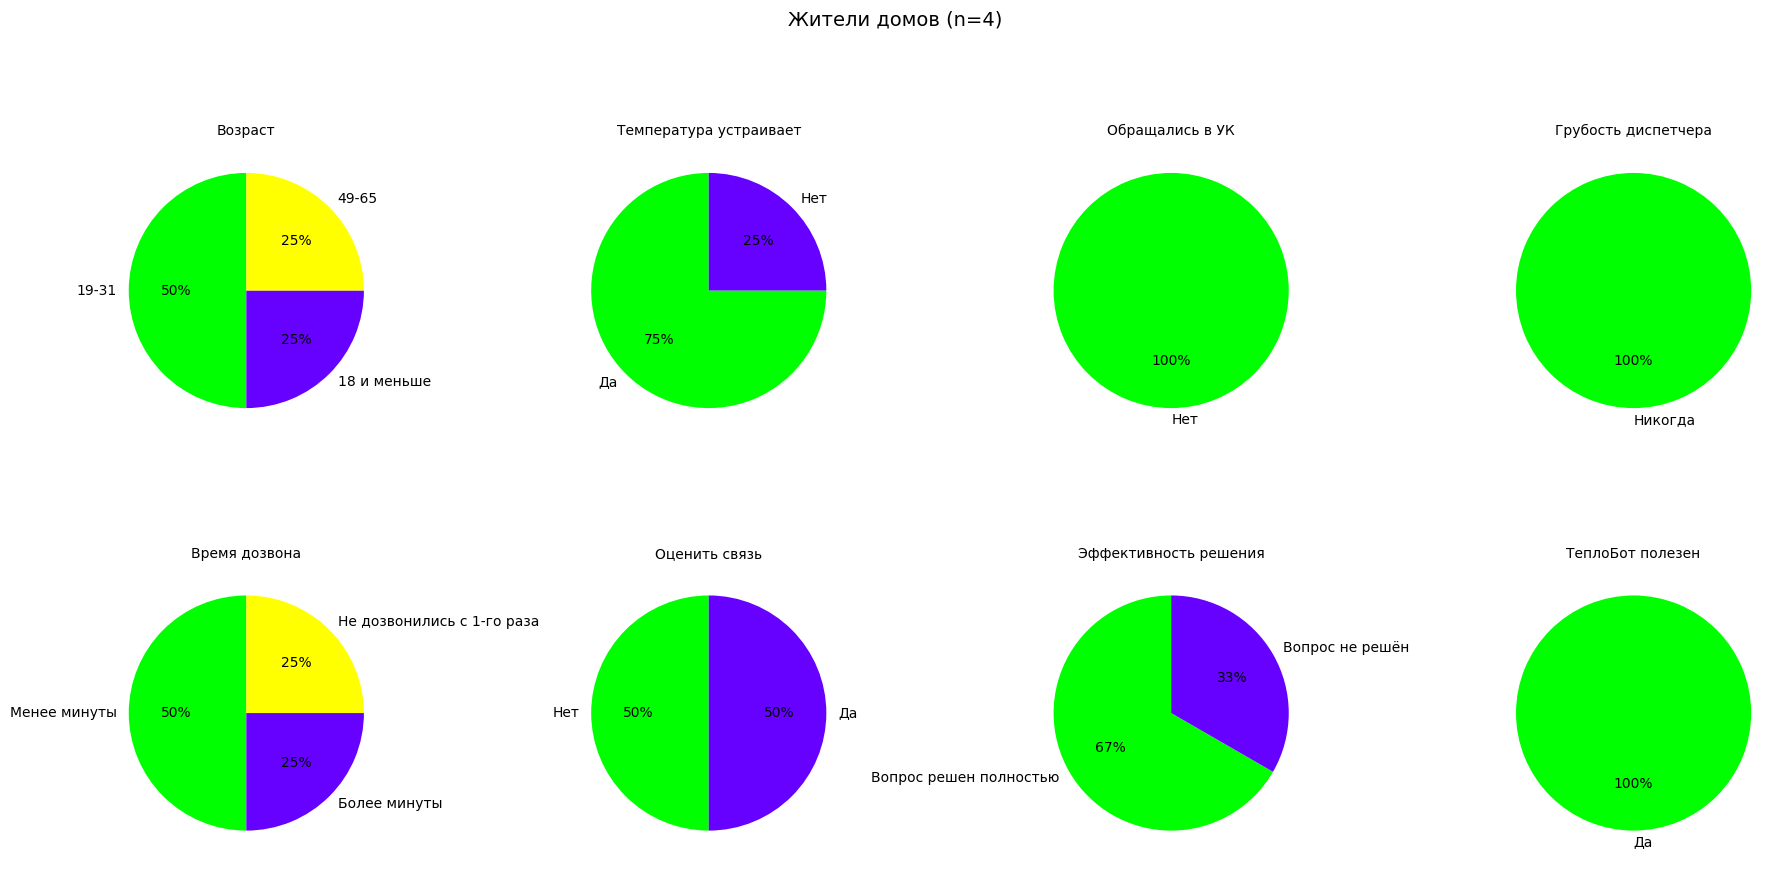

In [32]:

df_dom = df_all[df_all["жильё"] == "Дом"].reset_index(drop=True)

for col in ["температура_ок", "обращались_в_ук", "грубость_диспетчера",
            "оценить_связь", "эффективность_решения", "теплобот_полезен"]:
    df_dom[col] = df_dom[col].str.strip().str.capitalize()

df_dom["время_дозвона"] = df_dom["время_дозвона"].str.strip()
mask = df_dom["время_дозвона"].str.lower().isin(["менее 10 секунд", "около пол минуты"])
df_dom.loc[mask, "время_дозвона"] = "Менее минуты"


questions = [
    ("возраст", "Возраст"),
    ("температура_ок", "Температура устраивает"),
    ("обращались_в_ук", "Обращались в УК"),
    ("грубость_диспетчера", "Грубость диспетчера"),
    ("время_дозвона", "Время дозвона"),
    ("оценить_связь", "Оценить связь"),
    ("эффективность_решения", "Эффективность решения"),
    ("теплобот_полезен", "ТеплоБот полезен"),
]

colors = ['#00ff00', '#6600ff', '#ffff00', '#ff6600', '#ff0066', '#00cccc']

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, (col, title) in enumerate(questions):
    counts = df_dom[col].value_counts()
    axes[i].pie(counts, labels=counts.index, autopct="%1.0f%%",
                startangle=90, colors=colors[:len(counts)])
    axes[i].set_title(title, fontsize=10)

plt.suptitle("Жители домов (n=4)", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

Опрос работников УК

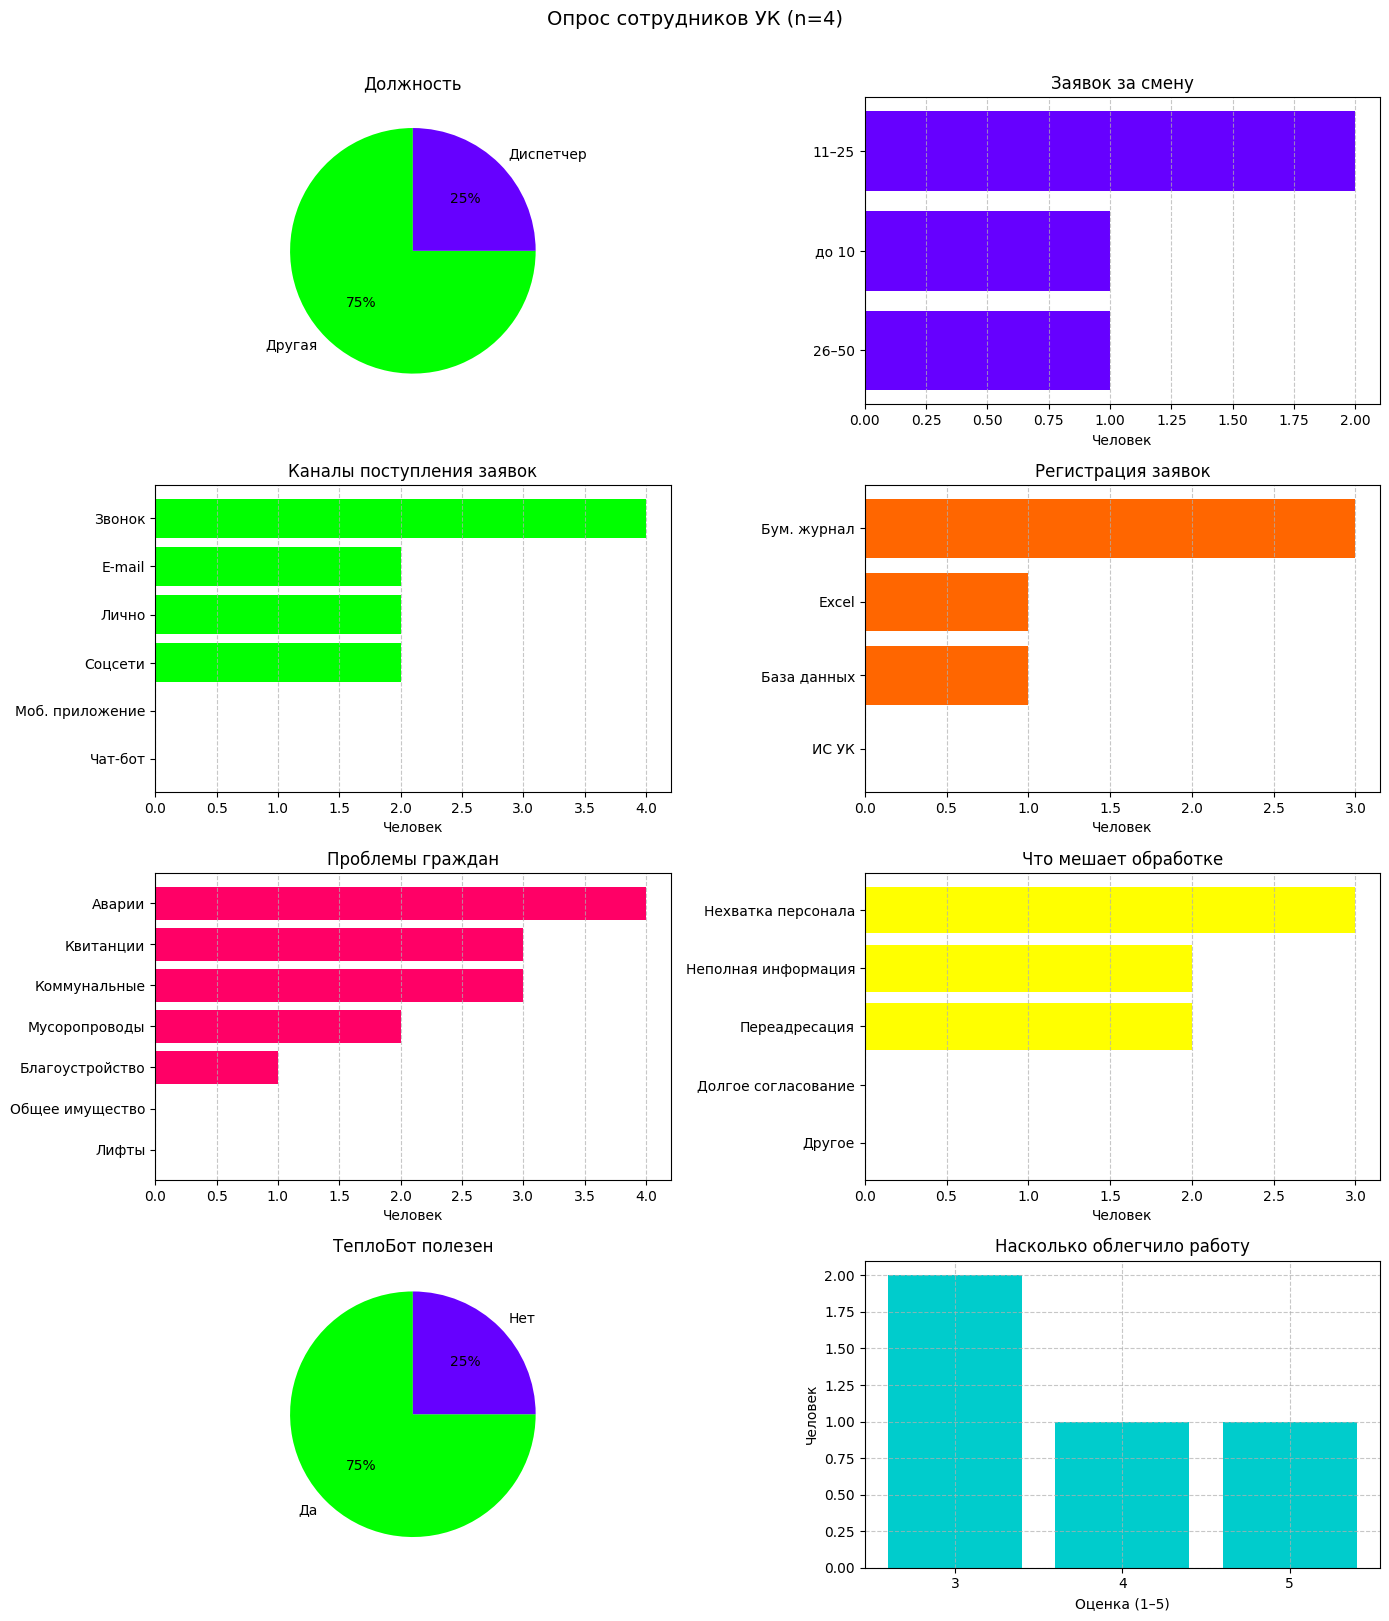

In [37]:

df = pd.read_csv("/content/2026-11-08 Опрос.csv")

df.columns = [
    "id", "должность", "заявок_за_смену",
    "kanal_zvonok", "kanal_pismo", "kanal_app",
    "kanal_lichno", "kanal_socseti", "kanal_chatbot",
    "kanal_k_masteram",
    "reg_is", "reg_excel", "reg_zhurnal", "reg_bd",
    "zadachi", "put_zayavki",
    "prob_kommunal", "prob_kvitancii", "prob_imushchestvo",
    "prob_avarii", "prob_lift", "prob_musor", "prob_blagoustroistvo",
    "mesho_personal", "mesho_infra", "mesho_pereadres",
    "mesho_soglasovanie", "mesho_drugoe", "mesho_drugoe_text",
    "teplobot_polezen", "oblegchilo", "predlozheniya"
]

df["должность"] = df["должность"].str.strip().str.capitalize()
df["заявок_за_смену"] = df["заявок_за_смену"].str.strip()
df["teplobot_polezen"] = df["teplobot_polezen"].str.strip().str.capitalize()

df["oblegchilo_num"] = df["oblegchilo"].str.extract(r'(\d)').astype(int)

def multi_count(df, cols, labels):
    """Считает, сколько раз каждая опция отмечена."""
    result = {}
    for col, label in zip(cols, labels):
        result[label] = df[col].notna().sum() - (df[col].astype(str).str.strip() == "").sum()
    return pd.Series(result).sort_values(ascending=False)

# Каналы поступления
kanal_cols = ["kanal_zvonok", "kanal_pismo", "kanal_app",
              "kanal_lichno", "kanal_socseti", "kanal_chatbot"]
kanal_labels = ["Звонок", "E-mail", "Моб. приложение",
                "Лично", "Соцсети", "Чат-бот"]
kanal_counts = multi_count(df, kanal_cols, kanal_labels)

# Регистрация
reg_cols = ["reg_is", "reg_excel", "reg_zhurnal", "reg_bd"]
reg_labels = ["ИС УК", "Excel", "Бум. журнал", "База данных"]
reg_counts = multi_count(df, reg_cols, reg_labels)

# Проблемы
prob_cols = ["prob_kommunal", "prob_kvitancii", "prob_imushchestvo",
             "prob_avarii", "prob_lift", "prob_musor", "prob_blagoustroistvo"]
prob_labels = ["Коммунальные", "Квитанции", "Общее имущество",
               "Аварии", "Лифты", "Мусоропроводы", "Благоустройство"]
prob_counts = multi_count(df, prob_cols, prob_labels)

# Что мешает
mesho_cols = ["mesho_personal", "mesho_infra", "mesho_pereadres",
              "mesho_soglasovanie", "mesho_drugoe"]
mesho_labels = ["Нехватка персонала", "Неполная информация",
                "Переадресация", "Долгое согласование", "Другое"]
mesho_counts = multi_count(df, mesho_cols, mesho_labels)


fig, axes = plt.subplots(4, 2, figsize=(14, 16))

# 1. Должность (pie)
ax = axes[0, 0]
counts = df["должность"].value_counts()
ax.pie(counts, labels=counts.index, autopct="%1.0f%%",
       startangle=90, colors=['#00ff00', '#6600ff'])
ax.set_title("Должность")

# 2. Заявок за смену (bar)
ax = axes[0, 1]
counts = df["заявок_за_смену"].value_counts()
ax.barh(counts.index[::-1], counts.values[::-1], color='#6600ff')
ax.set_title("Заявок за смену")
ax.set_xlabel("Человек")
ax.grid(axis='x', linestyle='--', alpha=0.7)

# 3. Каналы (bar)
ax = axes[1, 0]
ax.barh(kanal_counts.index[::-1], kanal_counts.values[::-1], color='#00ff00')
ax.set_title("Каналы поступления заявок")
ax.set_xlabel("Человек")
ax.grid(axis='x', linestyle='--', alpha=0.7)

# 4. Регистрация (bar)
ax = axes[1, 1]
ax.barh(reg_counts.index[::-1], reg_counts.values[::-1], color='#ff6600')
ax.set_title("Регистрация заявок")
ax.set_xlabel("Человек")
ax.grid(axis='x', linestyle='--', alpha=0.7)

# 5. Проблемы (bar)
ax = axes[2, 0]
ax.barh(prob_counts.index[::-1], prob_counts.values[::-1], color='#ff0066')
ax.set_title("Проблемы граждан")
ax.set_xlabel("Человек")
ax.grid(axis='x', linestyle='--', alpha=0.7)

# 6. Что мешает (bar)
ax = axes[2, 1]
ax.barh(mesho_counts.index[::-1], mesho_counts.values[::-1], color='#ffff00')
ax.set_title("Что мешает обработке")
ax.set_xlabel("Человек")
ax.grid(axis='x', linestyle='--', alpha=0.7)

# 7. ТеплоБот полезен (pie)
ax = axes[3, 0]
counts = df["teplobot_polezen"].value_counts()
ax.pie(counts, labels=counts.index, autopct="%1.0f%%",
       startangle=90, colors=['#00ff00', '#6600ff'])
ax.set_title("ТеплоБот полезен")

# 8. Насколько облегчило (bar)
ax = axes[3, 1]
counts = df["oblegchilo_num"].value_counts().sort_index()
ax.bar(counts.index.astype(str), counts.values, color='#00cccc')
ax.set_title("Насколько облегчило работу")
ax.set_xlabel("Оценка (1–5)")
ax.set_ylabel("Человек")
ax.grid(linestyle='--', alpha=0.7)

plt.suptitle("Опрос сотрудников УК (n=4)", fontsize=14, y=1.01)
plt.tight_layout()
plt.savefig("staff_subplots.png", dpi=150)

plt.show()